# FarmTech Solutions — Fase 6: Visão Computacional com YOLOv5 e CNN

**Integrantes do grupo:**
- Caroline Coelho Mendes — RM570370
- Leandro Paiva — RM572159
- Lucas Viana de Lima — RM571835

**Disciplina:** Fase 06 — Cap. 1 — O despertar da Rede Neural

**Classes:** `0 = vaca` · `1 = equipamento_pesado`  
**Dados:** 80 imagens (40 por classe) rotuladas no **Make Sense IA**; divisão **treino 64 / validação 8 / teste 8** (32 / 4 / 4 por classe).  
**Problema:** apoiar o monitoramento de fazendas identificando vacas e equipamentos pesados.

## Roteiro do notebook

| Seção | Conteúdo | Entrega |
|---|---|---|
| 1 | Ambiente, Google Drive e instalação do YOLOv5 | — |
| 2 | Auditoria do dataset e das anotações feitas no Make Sense | 1 |
| 3 | Treinamento da YOLOv5s customizada — 30 × 60 épocas | 1 |
| 4 | Validação e teste com as métricas oficiais da YOLO | 1 |
| 5 | Predições nas imagens de teste (prints para o cliente) | 1 |
| 6 | YOLOv5 padrão, pesos COCO | 2 |
| 7 | Comparação de detecção por IoU e F1 | 2 |
| 8 | CNN treinada do zero | 2 |
| 9 | Tempo de inferência | 2 |
| 10–11 | Comparação crítica, conclusões e recomendação | 1 e 2 |

## Objetivos e critérios da avaliação

- **Entrega 1:** adaptar a YOLOv5s ao dataset e treinar com **30** e **60** épocas, mantendo todos os outros parâmetros iguais. Registrar *precision*, *recall*, *mAP@0.5*, *mAP@0.5:0.95*, erros e tempo, e demonstrar as predições em imagens de teste.
- **Entrega 2:** comparar a YOLO customizada com a YOLOv5s padrão (pesos COCO) e com uma CNN construída do zero, discutindo facilidade de integração, precisão, tempo de treino e tempo de inferência.

> **Nota metodológica:** a YOLO detecta caixas; a CNN classifica a **imagem inteira**. Métricas de detecção (mAP, IoU) não podem ser comparadas diretamente com acurácia de classificação. A YOLO COCO reconhece `cow`, mas não tem uma classe `equipamento_pesado`; por isso a comparação comum de detecção é restrita à classe **vaca**. Em cenas com objetos não rotulados, as métricas de detecção podem subestimar a qualidade real; essa limitação é discutida nas seções 5 a 7.

**Reprodutibilidade:** semente fixa, mesma divisão e mesmos pesos iniciais `yolov5s.pt` nos dois experimentos. Os pesos treinados (YOLO e CNN) ficam salvos no Drive e são reaproveitados em novas execuções, de modo que os números citados no relatório continuem rastreáveis. Para treinar tudo novamente, use `FORCE_RETRAIN = True` e `CNN_RETREINAR = True` na seção 1.

## 1. Preparar o ambiente e o Google Drive

1. No Colab, escolha **Ambiente de execução → Alterar tipo de ambiente → GPU T4**.
2. Execute as células **em ordem** (*Ambiente de execução → Executar tudo*).
3. O notebook monta o Google Drive e procura o dataset em `Meu Drive/FarmTech_Fase6/dataset_yolo/`. Se não o encontrar, tenta, nesta ordem:
   - um ZIP do projeto no Meu Drive ou em `/content`, inclusive o ZIP gerado pelo botão **Code → Download ZIP** do GitHub;
   - clonar o repositório informado em `REPO_GITHUB`;
   - pedir o upload manual do ZIP.
4. Todos os resultados são gravados em `Meu Drive/FarmTech_Fase6/resultados_revisao/`.

As fotos são copiadas para o disco local do Colab com o lado maior limitado a **1280 px**. Isso acelera o treino sem alterar as anotações, pois as coordenadas YOLO são normalizadas (de 0 a 1).

In [1]:
# ── Bibliotecas usadas em todo o notebook ──────────────────────────────
from pathlib import Path                       # manipulação de caminhos de arquivos
import sys, subprocess, time, json, random, re, shutil, zipfile, hashlib
import numpy as np                             # cálculos numéricos
import pandas as pd                            # tabelas de métricas
import yaml                                    # arquivo data.yaml exigido pelo YOLOv5
import matplotlib.pyplot as plt                # gráficos
from matplotlib.patches import Rectangle       # desenho das caixas anotadas
from PIL import Image, ImageOps                # leitura e redimensionamento de imagens
from IPython.display import display, Markdown  # exibição de tabelas e textos gerados
from google.colab import drive                 # integração com o Google Drive

drive.mount('/content/drive')                  # autoriza o acesso ao Meu Drive

# ── Pastas do projeto ──────────────────────────────────────────────────
ROOT = Path('/content/drive/MyDrive/FarmTech_Fase6')   # pasta do projeto no Drive
ROOT.mkdir(parents=True, exist_ok=True)
DST = ROOT / 'dataset_yolo'                      # dataset original: imagens + rótulos do Make Sense
DATA = Path('/content/dataset_farmtech_local')   # cópia local usada no treino (disco mais rápido)
RESULTS = ROOT / 'resultados_revisao'            # pesos, métricas e figuras desta versão
RESULTS.mkdir(parents=True, exist_ok=True)

# Link do repositório do grupo no GitHub (usado só se o dataset não estiver no Drive)
REPO_GITHUB = ''   # ex.: 'https://github.com/usuario/nome-do-grupo'

# ── Parâmetros fixos dos experimentos ──────────────────────────────────
SEED = 42                                        # semente única para reprodutibilidade
random.seed(SEED)
np.random.seed(SEED)
CLASSES = ['vaca', 'equipamento_pesado']         # mesma ordem usada no Make Sense e no data.yaml
EXPECTED = {'train': 64, 'val': 8, 'test': 8}    # imagens esperadas em cada divisão
EXPECTED_BY_CLASS = {'train': {0: 32, 1: 32}, 'val': {0: 4, 1: 4}, 'test': {0: 4, 1: 4}}
EPOCHS_LIST = (30, 60)                           # as duas simulações pedidas no enunciado
IMG_SIZE = 640                                   # resolução de entrada da YOLO
MAX_SIDE = 1280                                  # lado máximo da cópia local das fotos
CONF = 0.25                                      # confiança mínima para aceitar uma predição
BATCH = 8                                        # tamanho do lote
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
FORCE_RETRAIN = False   # True: refaz os treinos da YOLO (os números podem variar um pouco)
CNN_RETREINAR = False   # True: refaz o treino da CNN do zero (os números podem variar)
print('Pasta do projeto:', ROOT)

Mounted at /content/drive
Pasta do projeto: /content/drive/MyDrive/FarmTech_Fase6


In [2]:
# ── Instalar o YOLOv5 (mesmo repositório usado no Cap. 3) ──────────────
YOLO_DIR = Path('/content/yolov5')
if not (YOLO_DIR / 'train.py').exists():         # clona só na primeira execução da sessão
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/ultralytics/yolov5.git',
                    str(YOLO_DIR)], check=True)
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', '-r', str(YOLO_DIR / 'requirements.txt')],
               check=True)                       # dependências oficiais do YOLOv5

import torch
assert torch.cuda.is_available(), 'Ative GPU T4 no menu Ambiente de execução antes do treinamento.'
DEVICE = '0'                                     # primeira GPU, no formato aceito pelos scripts YOLOv5
print('GPU:', torch.cuda.get_device_name(0))
commit = subprocess.check_output(['git', '-C', str(YOLO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
print('Versão do YOLOv5 (commit Git):', commit)

# Registra o ambiente para que os resultados possam ser rastreados depois
(RESULTS / 'ambiente.json').write_text(json.dumps({
    'yolov5_commit': commit, 'torch': torch.__version__, 'gpu': torch.cuda.get_device_name(0),
    'seed': SEED, 'img_size': IMG_SIZE, 'batch': BATCH, 'classes': CLASSES,
    'epochs': list(EPOCHS_LIST)
}, indent=2, ensure_ascii=False))

def run_yolo(script, args, capture=False):
    """Executa um script do YOLOv5 (train.py, val.py ou detect.py), como no terminal.
    capture=True guarda o log para extrair métricas; erros nunca são silenciados."""
    cmd = [sys.executable, str(YOLO_DIR / script)] + [str(a) for a in args]
    if not capture:
        subprocess.run(cmd, cwd=YOLO_DIR, check=True)   # o log aparece na saída da célula
        return ''
    p = subprocess.run(cmd, cwd=YOLO_DIR, text=True, stdout=subprocess.PIPE,
                       stderr=subprocess.STDOUT, check=False)
    if p.returncode != 0:                               # mostra o final do log em caso de erro
        raise RuntimeError(f'{script} falhou:\n{p.stdout[-6000:]}')
    return p.stdout

GPU: Tesla T4
Versão do YOLOv5 (commit Git): f9578796b8a64889aa9e66dc06914d19f40d338e


## 2. Verificação e preparação dos dados

**Rotulação no Make Sense IA.** As imagens foram anotadas com caixas retangulares (*Rect*) e exportadas em *Actions → Export Annotations → YOLO format*. O resultado é um arquivo `.txt` por imagem, com uma linha `classe centro_x centro_y largura altura` por objeto (coordenadas normalizadas de 0 a 1), salvo no Google Drive em `dataset_yolo/labels/{train,val,test}`. As imagens de validação e de teste também foram rotuladas, porque sem caixas de referência não é possível calcular mAP e IoU nessas etapas. Os prints da rotulação estão no README do repositório.

A estrutura é `dataset_yolo/images/{train,val,test}` e `dataset_yolo/labels/{train,val,test}`, acompanhada de `data.yaml`.

**Auditorias feitas pelo código:** quantidade de imagens por classe; correspondência 1:1 entre imagens e rótulos; IDs de classe válidos; coordenadas dentro da imagem; ausência de nomes duplicados; orientação EXIF. O processo **não** supõe que todas as vacas de uma cena estejam rotuladas: as anotações parciais já conhecidas são mantidas e tratadas como limitação.

> Treino, validação e teste ficam em pastas separadas. O teste não é usado para escolher hiperparâmetros nem pesos; os resultados de ambas as rodadas no teste aparecem apenas como avaliação final, como pede o enunciado.

In [3]:
# ── Localizar o dataset: Drive → ZIP → GitHub → upload ─────────────────
# Reconhece o ZIP original (FarmTech_Fase6/...) e também o ZIP do botão
# "Code → Download ZIP" do GitHub (NomeDoRepo-main/...).
IMAGENS_TREINO = re.compile(r'^(.*?)dataset_yolo/images/train/[^/]+\.(jpe?g|png|webp|bmp)$', re.I)

def copiar_dataset(origem, destino):
    """Copia a pasta dataset_yolo encontrada para o Drive, substituindo cópias incompletas."""
    if destino.exists():
        shutil.rmtree(destino)
    shutil.copytree(origem, destino)
    print(f'Dataset copiado para: {destino}')

def dataset_de_zip(arquivo, destino):
    """Extrai somente a pasta dataset_yolo de um ZIP, qualquer que seja a pasta-raiz."""
    try:
        with zipfile.ZipFile(arquivo) as z:
            # descobre o prefixo (pasta-raiz) que antecede dataset_yolo/
            prefixo = next((m.group(1) for n in z.namelist() if (m := IMAGENS_TREINO.match(n))), None)
            if prefixo is None:
                return False                                   # este ZIP não tem o dataset
            temp = Path('/content/_extracao_dataset')
            if temp.exists():
                shutil.rmtree(temp)
            for info in z.infolist():
                if info.filename.startswith(prefixo + 'dataset_yolo/'):
                    alvo = (temp / info.filename).resolve()
                    assert temp.resolve() in alvo.parents, f'Caminho inseguro no ZIP: {info.filename}'
                    z.extract(info, temp)                      # extrai arquivo por arquivo
        copiar_dataset(temp / prefixo / 'dataset_yolo', destino)
        return True
    except (zipfile.BadZipFile, OSError):
        return False

def obter_dataset(destino):
    """Garante destino/images/train. Ordem de busca: Drive, ZIP no Drive/Colab, git clone, upload."""
    if (destino / 'images' / 'train').is_dir():
        print(f'Dataset encontrado no Drive: {destino}')
        return
    pastas = [ROOT.parent, ROOT, Path('/content'), ROOT.parent / 'Downloads']
    zips = sorted({p for pasta in pastas if pasta.is_dir() for p in pasta.glob('*.zip')},
                  key=lambda p: p.stat().st_mtime, reverse=True)       # ZIPs mais recentes primeiro
    for arquivo in zips:
        if dataset_de_zip(arquivo, destino):
            print(f'Dataset extraído de: {arquivo}')
            return
    if REPO_GITHUB:                                                    # clona o repositório do grupo
        repo = Path('/content/repo_farmtech')
        if repo.exists():
            shutil.rmtree(repo)
        subprocess.run(['git', 'clone', '--depth', '1', REPO_GITHUB, str(repo)], check=True)
        achado = next((p for p in repo.rglob('dataset_yolo') if (p / 'images' / 'train').is_dir()), None)
        if achado is not None:
            copiar_dataset(achado, destino)
            return
    from google.colab import files                                     # último recurso: upload
    print('Dataset não encontrado. Selecione o ZIP do projeto (pacote original ou Download ZIP do GitHub):')
    for nome in files.upload():
        if dataset_de_zip(Path('/content') / nome, destino):
            return
    raise FileNotFoundError('Nenhuma fonte com dataset_yolo/images/train foi encontrada.')


obter_dataset(DST)

# ── Auditoria das 80 imagens e dos rótulos ──────────────────────────────
GT, registros = {s: {} for s in EXPECTED}, []           # GT guarda as caixas reais por imagem
for split, esperado in EXPECTED.items():
    img_dir, lab_dir = DST / 'images' / split, DST / 'labels' / split
    assert img_dir.is_dir() and lab_dir.is_dir(), f'Pasta ausente: {split}'
    imgs = sorted(p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXT)
    labels = sorted(lab_dir.glob('*.txt'))
    assert len(imgs) == esperado, f'{split}: esperado {esperado} imagens; encontrado {len(imgs)}'
    assert len(labels) == esperado, f'{split}: esperado {esperado} labels; encontrado {len(labels)}'
    stems = [p.stem for p in imgs]
    assert len(set(stems)) == len(stems), f'{split}: nomes iguais com extensões diferentes'
    assert {p.stem for p in labels} == set(stems), f'{split}: rótulo sem imagem ou imagem sem rótulo'
    for img in imgs:
        arquivo = lab_dir / f'{img.stem}.txt'
        linhas = [l.strip().split() for l in arquivo.read_text(encoding='utf8').splitlines() if l.strip()]
        assert linhas, f'{split}: anotação vazia em {arquivo.name}'
        caixas = []
        for linha in linhas:                                # cada linha = um objeto rotulado
            assert len(linha) == 5, f'Formato inválido: {arquivo.name} | {linha}'
            classe = int(linha[0]); valores = tuple(map(float, linha[1:]))
            xc, yc, w, h = valores
            assert classe in (0, 1) and 0 < w <= 1 and 0 < h <= 1, f'Classe/tamanho inválido: {arquivo.name}'
            assert all(0 <= v <= 1 for v in valores), f'Coordenada inválida: {arquivo.name}'
            assert (-1e-4 <= xc - w/2 and xc + w/2 <= 1.0001 and
                    -1e-4 <= yc - h/2 and yc + h/2 <= 1.0001), f'Caixa fora da imagem: {arquivo.name}'
            caixas.append((classe, valores))
        grupos = set(c for c, _ in caixas)
        assert len(grupos) == 1, f'Imagem com classes misturadas: revisar {img.name}'
        classe_img = next(iter(grupos))                      # classe da imagem (usada pela CNN)
        with Image.open(img) as im:
            largura, altura = im.size
            orientation = im.getexif().get(274, 1)            # tag 274 = orientação EXIF
            assert orientation == 1, f'EXIF com rotação em {img.name}; as caixas precisariam ser giradas.'
        GT[split][img.stem] = caixas
        registros.append({'split': split, 'classe_id': classe_img, 'classe': CLASSES[classe_img],
                          'imagem': f'dataset_yolo/images/{split}/{img.name}',
                          'rotulo': f'dataset_yolo/labels/{split}/{img.stem}.txt',
                          'stem': img.stem, 'n_caixas': len(caixas), 'largura': largura, 'altura': altura,
                          'megapixels': round(largura * altura / 1e6, 2)})

manifest_df = pd.DataFrame(registros)                     # inventário completo do dataset
manifest_df.to_csv(RESULTS / 'manifest_verificado.csv', index=False)
for split in EXPECTED:                                     # confere a divisão 32/4/4 por classe
    obtido = manifest_df[manifest_df.split == split].classe_id.value_counts().to_dict()
    assert obtido == EXPECTED_BY_CLASS[split], f'Divisão por classe incorreta ({split}): {obtido}'
print('Imagens por conjunto e classe:')
display(pd.crosstab(manifest_df.classe, manifest_df.split)[['train', 'val', 'test']])
print('Objetos anotados por conjunto e classe:')
display(manifest_df.pivot_table(index='classe', columns='split', values='n_caixas', aggfunc='sum')[['train', 'val', 'test']])
print('Megapixels:', manifest_df.megapixels.describe().round(2).to_dict())
assert len(manifest_df) == 80

Dataset encontrado no Drive: /content/drive/MyDrive/FarmTech_Fase6/dataset_yolo
Imagens por conjunto e classe:


split,train,val,test
classe,,,
equipamento_pesado,32,4,4
vaca,32,4,4


Objetos anotados por conjunto e classe:


split,train,val,test
classe,,,
equipamento_pesado,38,4,5
vaca,44,8,4


Megapixels: {'count': 80.0, 'mean': 0.93, 'std': 0.28, 'min': 0.2, '25%': 0.8, '50%': 1.09, '75%': 1.09, 'max': 1.31}


In [4]:
# ── Cópia local leve; os originais do Drive e as coordenadas não mudam ──
for split in EXPECTED:
    (DATA / 'images' / split).mkdir(parents=True, exist_ok=True)
    (DATA / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for r in manifest_df[manifest_df.split == split].itertuples():
        src = ROOT / r.imagem
        dst = DATA / 'images' / split / f'{r.stem}.jpg'
        with Image.open(src) as im:
            im = im.convert('RGB')                                   # garante 3 canais
            im.thumbnail((MAX_SIDE, MAX_SIDE), Image.Resampling.LANCZOS)  # reduz mantendo proporção
            im.save(dst, quality=90, optimize=True)
        shutil.copyfile(ROOT / r.rotulo, DATA / 'labels' / split / f'{r.stem}.txt')  # rótulo idêntico

# data.yaml com caminho absoluto, no formato pedido pelo YOLOv5
cfg = {'path': str(DATA), 'train': 'images/train', 'val': 'images/val', 'test': 'images/test',
       'nc': 2, 'names': CLASSES}
(DATA / 'data.yaml').write_text(yaml.safe_dump(cfg, allow_unicode=True), encoding='utf8')
size_mb = sum(p.stat().st_size for p in (DATA / 'images').rglob('*.jpg')) / 1e6
print(f'Dataset local: {size_mb:.1f} MB, imagens com no máximo {MAX_SIDE}px, rótulos preservados.')

# Conferência extra: a mesma foto não pode aparecer em duas divisões (vazamento de dados)
hashes = {}
for split in EXPECTED:
    for arq in (DATA / 'images' / split).glob('*.jpg'):
        digest = hashlib.sha256(arq.read_bytes()).hexdigest()       # "impressão digital" do arquivo
        hashes.setdefault(digest, []).append(f'{split}/{arq.name}')
duplicados = [v for v in hashes.values() if len(v) > 1]
if duplicados:
    print('ATENÇÃO: arquivos de imagem duplicados:', duplicados)
else:
    print('Nenhum arquivo de imagem exatamente duplicado na cópia local.')

Dataset local: 22.3 MB, imagens com no máximo 1280px, rótulos preservados.
Nenhum arquivo de imagem exatamente duplicado na cópia local.


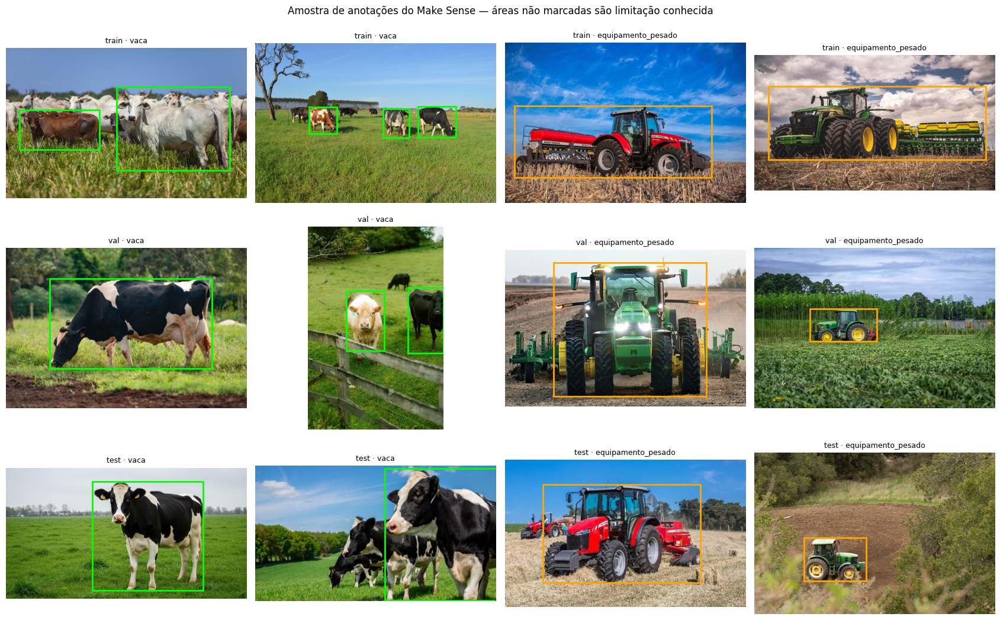

In [5]:
# ── Conferência visual: caixas feitas no Make Sense sobre imagens das 3 divisões ──
CORES = {0: 'lime', 1: 'orange'}                       # verde = vaca, laranja = equipamento
fig, axs = plt.subplots(3, 4, figsize=(17, 11))
amostras = [(s, cl) for s in EXPECTED for cl in (0, 0, 1, 1)]   # 2 vacas e 2 equipamentos por divisão
for ax, (split, grupo) in zip(axs.ravel(), amostras):
    posicao = 0 if ax in axs[:, ::2].ravel() else 1               # alterna a 1ª e a 2ª imagem da classe
    r = manifest_df[(manifest_df.split == split) & (manifest_df.classe_id == grupo)].iloc[posicao]
    with Image.open(DATA / 'images' / split / f'{r.stem}.jpg') as im:
        img = im.copy()
    w, h = img.size
    ax.imshow(img)
    ax.set_title(f'{split} · {r.classe}', fontsize=9)
    ax.axis('off')
    for cls, (xc, yc, bw, bh) in GT[split][r.stem]:            # converte centro/largura em canto superior
        ax.add_patch(Rectangle(((xc - bw/2) * w, (yc - bh/2) * h), bw * w, bh * h,
                               fill=False, edgecolor=CORES[cls], lw=2))
plt.suptitle('Amostra de anotações do Make Sense — áreas não marcadas são limitação conhecida')
plt.tight_layout()
plt.savefig(RESULTS / 'auditoria_caixas.png', dpi=125)
plt.show()

## 3. Entrega 1 — YOLOv5s customizada, 30 × 60 épocas

Os dois experimentos partem do **mesmo modelo pré-treinado `yolov5s.pt`**. Fixamos tamanho de imagem 640, batch 8, semente 42, dataset, hiperparâmetros padrão e *augmentations* do YOLOv5; a **única diferença planejada é o número de épocas**. Não há continuação do treino 30 → 60: ambos começam dos mesmos pesos iniciais.

- **Treinamento:** ocorre no disco local do Colab, para evitar a lentidão do Drive.
- **Validação:** o YOLO avalia o conjunto `val` a cada época e guarda o melhor checkpoint em `best.pt`.
- **Preservação:** após cada treino completo, os resultados são copiados para o Drive.
- **Tempo:** medido com `time.perf_counter()`; **não inclui** a cópia dos arquivos para o Drive.
- **Reexecução:** se `best.pt` já existir em `resultados_revisao/`, ele é reaproveitado. Para refazer, use `FORCE_RETRAIN = True` na seção 1.

**Onde ficam os resultados?** No Cap. 3, o YOLOv5 grava em `yolov5/runs/train/exp`, `exp2`, `exp3`… e o log termina com a linha *“Results saved to …”*. Aqui usamos `--project` e `--name` para dar nomes fixos (`epocas_30` e `epocas_60`) e copiamos cada pasta para o Drive. Assim a pasta de cada experimento não muda de número entre sessões do Colab e não se perde quando a sessão termina. A linha *“Results saved to …”* continua aparecendo no log de cada treino, indicando o caminho exato.

> Aumentar de 30 para 60 épocas **não garante** melhoria. Procure sinais de queda do erro no treino sem ganho equivalente na validação (*possível overfitting*), lembrando que 8 fotos de validação tornam esse diagnóstico instável.

In [6]:
# ── Treinar (ou reaproveitar) as duas YOLOs customizadas ────────────────
RUNS_LOCAL = Path('/content/farmtech_treinos')   # equivalente ao yolov5/runs/train do Cap. 3
RUNS_DRIVE = RESULTS / 'yolo_custom'             # cópia permanente no Drive
RUNS_LOCAL.mkdir(parents=True, exist_ok=True)
RUNS_DRIVE.mkdir(parents=True, exist_ok=True)
train_seconds = {}                               # tempo de treino de cada rodada
for ep in EPOCHS_LIST:
    destino = RUNS_DRIVE / f'epocas_{ep}'
    pasta_local = RUNS_LOCAL / f'epocas_{ep}'
    checkpoint = destino / 'weights' / 'best.pt'
    tempo = destino / 'tempo_treinamento_segundos.txt'
    if checkpoint.exists() and tempo.exists() and not FORCE_RETRAIN:
        print(f'{ep} épocas: resultado já existe no Drive; reaproveitando.')
    else:
        if pasta_local.exists():
            shutil.rmtree(pasta_local)                       # começa de uma pasta limpa
        inicio = time.perf_counter()
        run_yolo('train.py', ['--img', IMG_SIZE, '--batch-size', BATCH, '--epochs', ep,
                              '--data', DATA / 'data.yaml', '--weights', 'yolov5s.pt', '--seed', SEED,
                              '--device', DEVICE, '--workers', 2, '--cache', 'ram',
                              '--project', RUNS_LOCAL, '--name', f'epocas_{ep}', '--exist-ok'])
        segundos = time.perf_counter() - inicio
        assert (pasta_local / 'weights' / 'best.pt').exists(), f'Treinamento de {ep} épocas sem best.pt'
        if destino.exists():
            shutil.rmtree(destino)
        shutil.copytree(pasta_local, destino)                # salva pesos, results.csv e curvas
        tempo.write_text(f'{segundos:.2f}')
    train_seconds[ep] = float(tempo.read_text())
    print(f'{ep} épocas: {train_seconds[ep]/60:.2f} minutos | best.pt em {checkpoint}')

30 épocas: 1.46 minutos | best.pt em /content/drive/MyDrive/FarmTech_Fase6/resultados_revisao/yolo_custom/epocas_30/weights/best.pt
60 épocas: 2.01 minutos | best.pt em /content/drive/MyDrive/FarmTech_Fase6/resultados_revisao/yolo_custom/epocas_60/weights/best.pt


## 4. Validação e teste — métricas oficiais

Para **cada** YOLO treinada, rodamos `val.py` sobre a validação e sobre o teste, com os mesmos tamanhos e lotes. Registramos *precision*, *recall*, **mAP@0.5** e **mAP@0.5:0.95**, e calculamos o F1 a partir de P e R.

- **Validação** orienta as decisões e a escolha dos pesos.
- **Teste** estima o desempenho final em fotos nunca usadas no treino; não é usado para ajustar o modelo.

Os logs completos ficam salvos para auditoria.

In [7]:
# ── Rodar val.py e extrair as métricas da tabela impressa pelo YOLOv5 ───
EVAL_DIR = RESULTS / 'avaliacoes'
EVAL_DIR.mkdir(parents=True, exist_ok=True)
# Linha do log: classe, nº de imagens, nº de objetos, P, R, mAP50, mAP50-95
pat = re.compile(r'^\s*(all|vaca|equipamento_pesado)\s+(\d+)\s+(\d+)\s+([0-9.eE+-]+)\s+'
                 r'([0-9.eE+-]+)\s+([0-9.eE+-]+)\s+([0-9.eE+-]+)')
linhas = []
for ep in EPOCHS_LIST:
    weights = RUNS_DRIVE / f'epocas_{ep}' / 'weights' / 'best.pt'
    for split in ('val', 'test'):
        log = run_yolo('val.py', ['--weights', weights, '--data', DATA / 'data.yaml',
                                  '--imgsz', IMG_SIZE, '--batch-size', BATCH, '--task', split,
                                  '--device', DEVICE, '--verbose', '--project', EVAL_DIR,
                                  '--name', f'ep{ep}_{split}', '--exist-ok'], capture=True)
        (EVAL_DIR / f'ep{ep}_{split}.log').write_text(log, encoding='utf8')   # guarda o log completo
        limpo = re.sub(r'\x1b\[[0-9;]*[a-zA-Z]', '', log).replace('\r', '\n')  # remove cores do terminal
        encontrado = {}
        for linha in limpo.splitlines():
            m = pat.match(linha.strip())
            if m:
                nome, imagens, n_objs, P, R, AP50, AP = m.groups()
                encontrado[nome] = dict(epocas=ep, split=split, classe=nome, imagens=int(imagens),
                                        objetos=int(n_objs), precision=float(P), recall=float(R),
                                        mAP50=float(AP50), mAP50_95=float(AP))
        if 'all' not in encontrado:                     # falha explícita se o formato do log mudar
            raise RuntimeError(f'Métricas não encontradas. Veja {EVAL_DIR/f"ep{ep}_{split}.log"}.\n{limpo[-1500:]}')
        linhas.extend(encontrado.values())

metrics_df = pd.DataFrame(linhas)
# F1 = média harmônica entre precision e recall
metrics_df['F1'] = (2 * metrics_df.precision * metrics_df.recall /
                    (metrics_df.precision + metrics_df.recall).replace(0, np.nan)).fillna(0)
metrics_df.to_csv(RESULTS / 'metricas_val_test.csv', index=False)
print('Métricas gerais:')
display(metrics_df.query("classe == 'all'").reset_index(drop=True))
print('Detalhamento por classe:')
display(metrics_df.query("classe != 'all'").reset_index(drop=True))

Métricas gerais:


,epocas,split,classe,imagens,objetos,precision,recall,mAP50,mAP50_95,F1
0,30,val,all,8,12,1.000,0.856,0.964,0.613,0.922414
1,30,test,all,8,9,0.911,0.575,0.819,0.555,0.705013
2,60,val,all,8,12,0.782,1.000,0.981,0.676,0.877666
3,60,test,all,8,9,0.867,0.786,0.924,0.637,0.824515


Detalhamento por classe:


,epocas,split,classe,imagens,objetos,precision,recall,mAP50,mAP50_95,F1
0,30,val,vaca,8,8,1.000,0.712,0.933,0.565,0.831776
1,30,val,equipamento_pesado,8,4,0.999,1.000,0.995,0.661,0.999500
2,30,test,vaca,8,4,0.911,0.750,0.912,0.719,0.822697
3,30,test,equipamento_pesado,8,5,0.910,0.400,0.726,0.392,0.555725
4,60,val,vaca,8,8,0.798,1.000,0.967,0.752,0.887653
5,60,val,equipamento_pesado,8,4,0.767,1.000,0.995,0.599,0.868138
6,60,test,vaca,8,4,1.000,0.972,0.995,0.769,0.985801
7,60,test,equipamento_pesado,8,5,0.734,0.600,0.853,0.505,0.660270


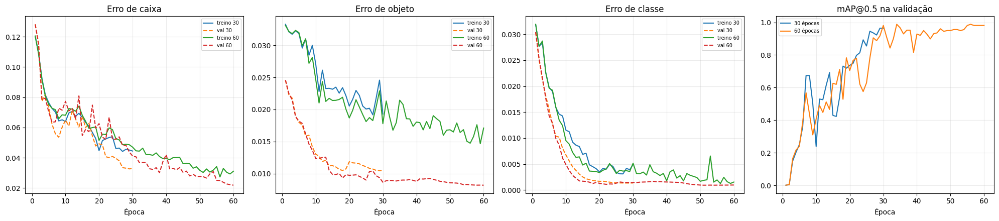

Diagnóstico exploratório (não é prova isolada de overfitting):


,épocas_planejadas,época_melhor_val_box,época_melhor_val_mAP50,train_box_final,val_box_final,val_box_mínima
0,30,29,29,0.0444,0.0328,0.0326
1,60,60,34,0.0311,0.0218,0.0218


In [8]:
# ── Curvas de erro e de mAP lidas do results.csv de cada treino ────────
historicos = {}
for ep in EPOCHS_LIST:
    df = pd.read_csv(RUNS_DRIVE / f'epocas_{ep}' / 'results.csv')
    df.columns = df.columns.str.strip()                  # o YOLOv5 grava nomes com espaços
    historicos[ep] = df
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ep, df in historicos.items():
    x = np.arange(1, len(df) + 1)
    for ax, perda in zip(axs[:3], ['box_loss', 'obj_loss', 'cls_loss']):   # 3 componentes do erro
        ax.plot(x, df[f'train/{perda}'], label=f'treino {ep}')
        ax.plot(x, df[f'val/{perda}'], '--', label=f'val {ep}')
    axs[3].plot(x, df['metrics/mAP_0.5'], label=f'{ep} épocas')
for ax, titulo in zip(axs, ['Erro de caixa', 'Erro de objeto', 'Erro de classe', 'mAP@0.5 na validação']):
    ax.set_title(titulo); ax.set_xlabel('Época'); ax.legend(fontsize=7); ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig(RESULTS / 'curvas_30_60.png', dpi=130)
plt.show()

# Resumo numérico das curvas (ajuda a procurar sinais de overfitting)
Diag = []
for ep, df in historicos.items():
    Diag.append({'épocas_planejadas': ep,
                 'época_melhor_val_box': int(df['val/box_loss'].idxmin()) + 1,
                 'época_melhor_val_mAP50': int(df['metrics/mAP_0.5'].idxmax()) + 1,
                 'train_box_final': float(df['train/box_loss'].iloc[-1]),
                 'val_box_final': float(df['val/box_loss'].iloc[-1]),
                 'val_box_mínima': float(df['val/box_loss'].min())})
print('Diagnóstico exploratório (não é prova isolada de overfitting):')
display(pd.DataFrame(Diag).round(4))

### 4.1 Leitura das curvas

Nas duas rodadas, os erros de treino e de validação caem juntos, e o erro de caixa da validação continua diminuindo até a última época; a rodada de 30 épocas ainda estava melhorando quando o treino parou. Na rodada de 60 épocas, o mAP@0.5 de validação chega perto do teto (≈0,99) por volta da época 34 e depois oscila entre ≈0,93 e ≈0,98: com apenas 8 imagens de validação, uma caixa a mais ou a menos já muda o valor. **Não há sinal claro de overfitting** — o erro de validação não sobe enquanto o de treino cai. Como o `best.pt` é escolhido pelo *fitness* de validação do YOLOv5 (combinação de mAP@0.5 e mAP@0.5:0.95), o modelo final de 60 épocas não é necessariamente o da última época. As curvas devem ser lidas como tendência, não como prova.

## 5. Inferência — imagens do conjunto de teste

Usamos as **8 imagens de teste**, confiança `0.25` e resolução `640`, gerando imagens com caixas e arquivos `.txt` com classes, coordenadas e escores.

**Equivalência com `yolov5/runs/detect/expX`.** O enunciado cita a pasta `yolov5/runs/detect/expX`, em que X aumenta a cada execução. Aqui o `detect.py` recebe `--project` e `--name`, então as predições ficam em `resultados_revisao/predicoes_testes/ep30` e `.../ep60` no Drive. O log do `detect.py` mostra a linha *“Results saved to …”* com o caminho exato. As grades abaixo são os prints usados para convencer o cliente fictício.

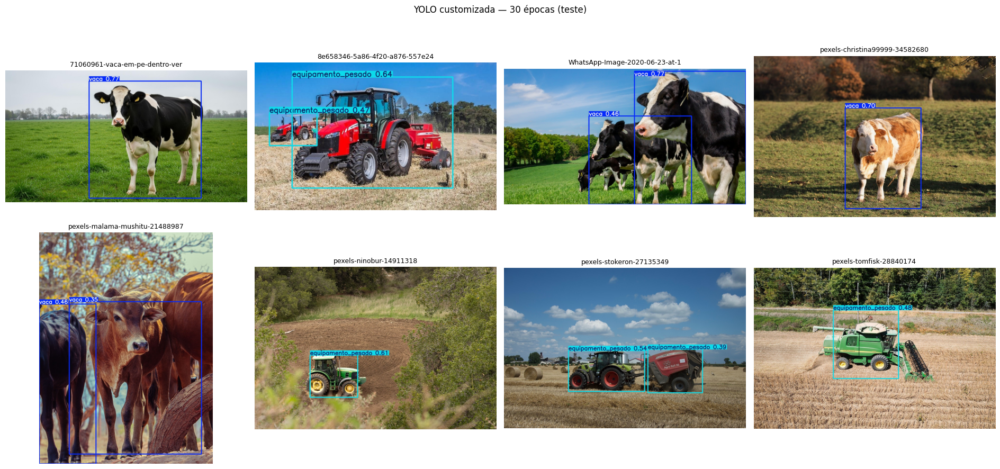

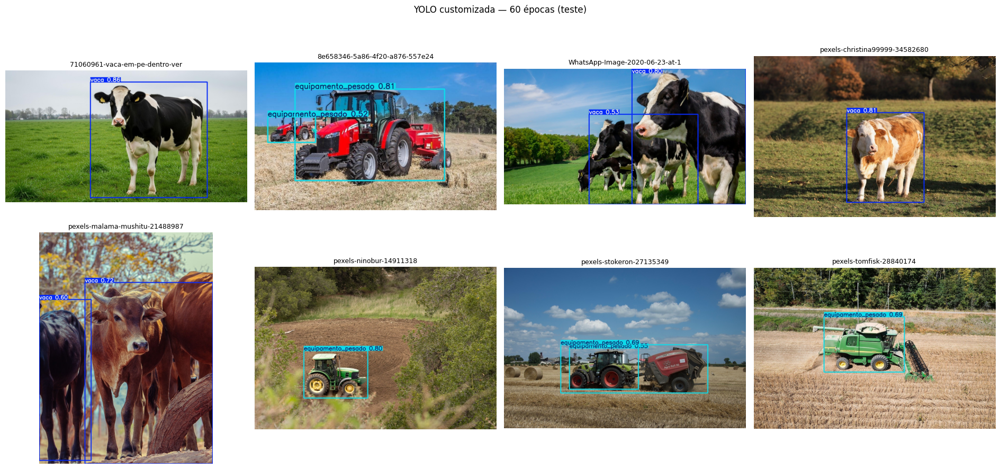

In [9]:
# ── Rodar detect.py nas 8 imagens de teste e montar uma grade de prints ──
PRED = RESULTS / 'predicoes_testes'                  # equivalente a yolov5/runs/detect
PRED.mkdir(parents=True, exist_ok=True)

def show_grid(folder, titulo):
    """Mostra as 8 imagens processadas em uma grade 2x4 e salva a figura na mesma pasta."""
    arquivos = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)
    assert len(arquivos) == 8, f'Esperávamos 8 imagens renderizadas em {folder}: {len(arquivos)}'
    fig, axs = plt.subplots(2, 4, figsize=(19, 9))
    for ax, p in zip(axs.ravel(), arquivos):
        with Image.open(p) as im:
            ax.imshow(im.copy())
        ax.axis('off'); ax.set_title(p.stem[:30], fontsize=9)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(Path(folder) / 'grade_resultados.png', dpi=120)
    plt.show()

for ep in EPOCHS_LIST:
    pasta = PRED / f'ep{ep}'
    if pasta.exists():
        shutil.rmtree(pasta)                          # evita sobras de predições anteriores
    run_yolo('detect.py', ['--weights', RUNS_DRIVE / f'epocas_{ep}' / 'weights' / 'best.pt',
                           '--source', DATA / 'images' / 'test', '--imgsz', IMG_SIZE,
                           '--conf-thres', CONF, '--device', DEVICE, '--save-txt', '--save-conf',
                           '--project', PRED, '--name', f'ep{ep}', '--exist-ok'])
    show_grid(pasta, f'YOLO customizada — {ep} épocas (teste)')

### 5.1 Leitura das predições (o que mostrar ao cliente)

- **Acertos claros:** nas duas versões, as vacas isoladas no pasto e os tratores em campo aberto são localizados com caixas justas e com a classe correta.
- **Confiança:** com 60 épocas, a maioria dos acertos recebe escores mais altos — por exemplo, o trator vermelho (≈0,81 contra ≈0,64), o trator verde em meio à vegetação (≈0,80 contra ≈0,61) e a vaca isolada (≈0,86 contra ≈0,77) —, coerente com o ganho de mAP no teste.
- **Colheitadeira (`pexels-tomfisk`):** nas duas versões a caixa cobre o corpo da máquina e deixa de fora a plataforma de corte lateral; com 60 épocas a confiança é maior (≈0,69 contra ≈0,48). Máquinas com acessórios longos são um ponto a reforçar com mais exemplos.
- **Trator com enfardadeira (`pexels-stokeron`):** com 30 épocas, os dois equipamentos aparecem em caixas separadas (a enfardadeira com confiança baixa); com 60 épocas, além da caixa do trator surge uma caixa larga que engloba trator e enfardadeira juntos. É um erro de separação entre objetos encostados.
- **Animais sobrepostos:** na foto do WhatsApp, nas duas versões uma caixa de confiança média cobre várias vacas ao mesmo tempo, em vez de separá-las.
- **Falsos positivos aparentes:** o trator vermelho ao fundo de `8e658346` e as várias reses de `pexels-malama-mushitu` são objetos **reais**, mas cada uma dessas imagens tem apenas **uma** caixa rotulada. Detectá-los conta como FP nas métricas, mesmo sendo correto — efeito da rotulação parcial discutido na seção 7.

**Mensagem ao cliente:** o modelo já localiza bem os casos típicos, e o treino mais longo deixou as detecções mais confiantes. Os erros restantes concentram-se em objetos encostados ou sobrepostos, exatamente onde mais imagens e rótulos completos fariam diferença.

## 6. Entrega 2 — YOLO padrão (pesos COCO, sem customização)

**Qual “YOLO tradicional” usamos e por quê.** No hands-on do Cap. 10, a YOLO pré-treinada é executada como YOLOv3/darknet com pesos COCO. Aqui usamos a **YOLOv5s com os pesos COCO originais (`yolov5s.pt`)**, sem nenhum ajuste. É o mesmo tipo de solução — uma rede pronta, treinada nas 80 classes do MS COCO —, mas na mesma versão, biblioteca, resolução (640 px) e limiar de confiança da YOLO customizada. Assim, a diferença observada se deve à **customização com as nossas imagens**, e não a uma troca de versão ou de framework. Além disso, `yolov5s.pt` é exatamente o ponto de partida dos treinos da seção 3, o que torna direta a comparação “antes × depois da customização”.

O COCO reconhece **`cow` (ID 19)**, mas não tem categoria para tratores, colheitadeiras e enfardadeiras. A classe `truck` (ID 7) aparece como aproximação visual, porém **não é equivalente** a `equipamento_pesado`. Por isso a comparação principal entre as três YOLOs é restrita a **vacas**. Como análise exploratória, a seção 7 também mostra o resultado tratando `truck` como “equipamento”, deixando claro que se trata de uma aproximação. Tempo de treinamento da YOLO padrão neste projeto: **0** (modelo já disponível).

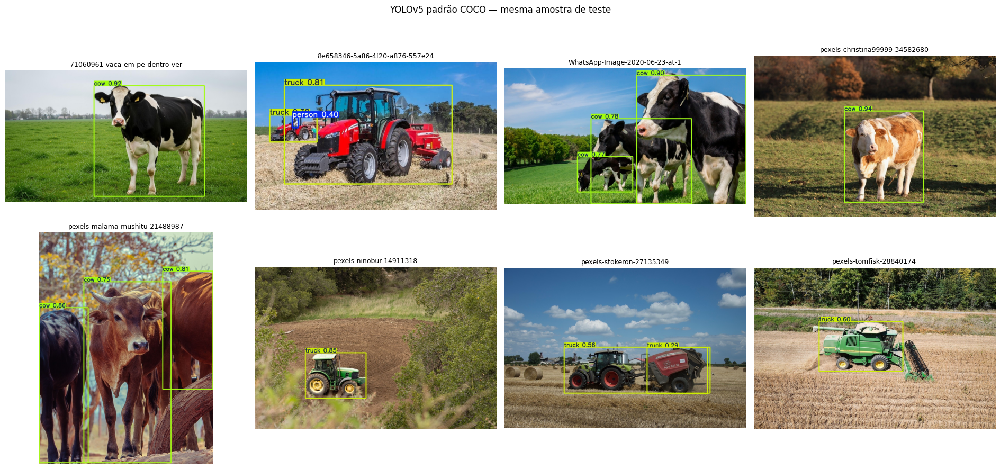

In [10]:
# ── YOLOv5s com pesos COCO, nas mesmas 8 imagens e com a mesma confiança ──
BASELINE = RESULTS / 'yolo_padrao'
pasta = BASELINE / 'coco'
if pasta.exists():
    shutil.rmtree(pasta)
run_yolo('detect.py', ['--weights', 'yolov5s.pt', '--source', DATA / 'images' / 'test',
                       '--imgsz', IMG_SIZE, '--conf-thres', CONF, '--device', DEVICE,
                       '--save-txt', '--save-conf', '--project', BASELINE, '--name', 'coco', '--exist-ok'])
show_grid(pasta, 'YOLOv5 padrão COCO — mesma amostra de teste')

# Mapeamentos de classes COCO → classes do projeto
MAP_COW_COCO = {19: 0}            # comparação principal: cow (19) = vaca (0)
MAP_PROXY_COCO = {19: 0, 7: 1}    # exploratório: truck (7) tratado como equipamento_pesado (1)

### 6.1 Leitura das predições da YOLO padrão

- A YOLO COCO encontra **todas** as vacas, inclusive as que não foram rotuladas (as três reses de `pexels-malama-mushitu` e as vacas ao fundo na foto do WhatsApp), em geral com confiança alta. Por isso parte dos seus “falsos positivos” na seção 7 são, na verdade, animais reais sem caixa de referência.
- Tratores, enfardadeira e colheitadeira aparecem como **`truck`**, e o operador dentro da cabine aparece como `person`. O modelo “vê” as máquinas, mas com uma taxonomia que não atende ao cliente: um sistema de monitoramento de fazenda precisa distinguir máquina agrícola de caminhão.

## 7. Comparação de detecção usando IoU e F1

Para cada imagem, comparamos as caixas previstas com as anotadas:
- **TP** = objeto e classe corretos com IoU acima do limite;
- **FP** = caixa prevista sem correspondência;
- **FN** = objeto anotado que não foi encontrado.

Cada caixa real é associada a no máximo uma predição, priorizando a de maior confiança. Apresentamos IoU `≥ 0,50` e `≥ 0,75`. É uma **métrica complementar**: não substitui o mAP oficial, que considera vários limiares de confiança. A comparação entre as três YOLOs é feita **só para vaca**; a linha “COCO (truck como equipamento)” da segunda tabela é apenas exploratória.

**Limitação fundamental:** há objetos reais sem caixa anotada, então algumas detecções corretas são contadas como **FP**. Os resultados refletem a qualidade **em relação às anotações disponíveis**, não uma estimativa definitiva para produção.

In [11]:
# ── Funções de comparação caixa a caixa ─────────────────────────────────
def to_xyxy(b):
    """Converte (centro_x, centro_y, largura, altura) em (x1, y1, x2, y2)."""
    x, y, w, h = b
    return (x - w/2, y - h/2, x + w/2, y + h/2)

def iou(a, b):
    """Intersection over Union entre duas caixas no formato YOLO normalizado."""
    ax1, ay1, ax2, ay2 = to_xyxy(a)
    bx1, by1, bx2, by2 = to_xyxy(b)
    iw = max(0., min(ax2, bx2) - max(ax1, bx1))          # largura da interseção
    ih = max(0., min(ay2, by2) - max(ay1, by1))          # altura da interseção
    inter = iw * ih
    union = (ax2 - ax1) * (ay2 - ay1) + (bx2 - bx1) * (by2 - by1) - inter
    return inter / union if union > 0 else 0.

def read_preds(folder, stem, mapping=None):
    """Lê o .txt de predições do detect.py; mapping converte classes COCO nas do projeto."""
    f = Path(folder) / 'labels' / f'{stem}.txt'
    pred = []
    if not f.exists():
        return pred                                       # imagem sem nenhuma detecção
    for line in f.read_text().splitlines():
        parts = line.split()
        if len(parts) < 6:
            raise ValueError(f'Predição sem confiança: {f}')
        c = int(parts[0])
        if mapping is not None:
            if c not in mapping:
                continue                                  # ignora classes sem equivalente
            c = mapping[c]
        pred.append((c, tuple(map(float, parts[1:5])), float(parts[5])))
    return pred

def avaliar_iou(folder, threshold=.5, mapping=None, only_class=None, split='test'):
    """Conta TP, FP e FN comparando predições e caixas reais com um limiar de IoU."""
    TP = FP = FN = 0
    ious = []
    for stem, reais in GT[split].items():
        if only_class is not None:
            reais = [(c, b) for c, b in reais if c == only_class]
        pred = read_preds(folder, stem, mapping)
        if only_class is not None:
            pred = [p for p in pred if p[0] == only_class]
        matched = set()
        for classe, box, conf in sorted(pred, key=lambda p: -p[2]):   # maior confiança primeiro
            melhor, indice = 0., None
            for j, (classe_real, box_real) in enumerate(reais):
                if j in matched or classe != classe_real:
                    continue
                v = iou(box, box_real)
                if v > melhor:
                    melhor, indice = v, j
            if indice is not None and melhor >= threshold:
                TP += 1; matched.add(indice); ious.append(melhor)
            else:
                FP += 1
        FN += len(reais) - len(matched)                  # caixas reais sem correspondência
    P = TP / (TP + FP) if TP + FP else 0.
    R = TP / (TP + FN) if TP + FN else 0.
    return {'TP': TP, 'FP': FP, 'FN': FN, 'precision': P, 'recall': R,
            'F1': 2 * P * R / (P + R) if P + R else 0.,
            'IoU_medio_TP': float(np.mean(ious)) if ious else 0.}

# ── Tabela 1: só a classe vaca, comum às três YOLOs ─────────────────────
sources = {'YOLO customizada 30 ép.': (PRED / 'ep30', None),
           'YOLO customizada 60 ép.': (PRED / 'ep60', None),
           'YOLO padrão COCO (cow)': (BASELINE / 'coco', MAP_COW_COCO)}
linhas = []
for nome, (pasta, mapping) in sources.items():
    for thr in (0.5, 0.75):
        rec = avaliar_iou(pasta, threshold=thr, mapping=mapping, only_class=0)
        linhas.append({'modelo': nome, 'classe_avaliada': 'vaca', 'IoU_min': thr, **rec})
cow_comparison = pd.DataFrame(linhas)
cow_comparison.to_csv(RESULTS / 'comparacao_vacas_iou.csv', index=False)
print('Tabela 1 — detecção de vacas (comparação principal):')
display(cow_comparison.round(3))

# ── Tabela 2: as duas classes juntas (customizadas + COCO exploratório) ──
linhas_custom = []
for ep in EPOCHS_LIST:
    for limiar in (.5, .75):
        linhas_custom.append({'epocas': ep, 'IoU_min': limiar,
                              **avaliar_iou(PRED / f'ep{ep}', threshold=limiar)})
custom_iou = pd.DataFrame(linhas_custom)
custom_iou.to_csv(RESULTS / 'comparacao_custom_duas_classes.csv', index=False)
proxy = pd.DataFrame([{'modelo': 'COCO (truck como equipamento) — exploratório', 'IoU_min': limiar,
                       **avaliar_iou(BASELINE / 'coco', threshold=limiar, mapping=MAP_PROXY_COCO)}
                      for limiar in (.5, .75)])
duas_classes = pd.concat([custom_iou.assign(modelo=lambda d: 'YOLO customizada ' + d.epocas.astype(str) + ' ép.')
                          .drop(columns='epocas'), proxy], ignore_index=True)
duas_classes.to_csv(RESULTS / 'comparacao_duas_classes.csv', index=False)
print('Tabela 2 — duas classes juntas:')
display(duas_classes[['modelo', 'IoU_min', 'TP', 'FP', 'FN', 'precision', 'recall', 'F1', 'IoU_medio_TP']].round(3))

Tabela 1 — detecção de vacas (comparação principal):


,modelo,classe_avaliada,IoU_min,TP,FP,FN,precision,recall,F1,IoU_medio_TP
0,YOLO customizada 30 ép.,vaca,0.50,4,2,0,0.667,1.00,0.800,0.832
1,YOLO customizada 30 ép.,vaca,0.75,3,3,1,0.500,0.75,0.600,0.921
2,YOLO customizada 60 ép.,vaca,0.50,4,2,0,0.667,1.00,0.800,0.856
3,YOLO customizada 60 ép.,vaca,0.75,3,3,1,0.500,0.75,0.600,0.938
4,YOLO padrão COCO (cow),vaca,0.50,4,4,0,0.500,1.00,0.667,0.946
5,YOLO padrão COCO (cow),vaca,0.75,4,4,0,0.500,1.00,0.667,0.946


Tabela 2 — duas classes juntas:


,modelo,IoU_min,TP,FP,FN,precision,recall,F1,IoU_medio_TP
0,YOLO customizada 30 ép.,0.50,8,4,1,0.667,0.889,0.762,0.798
1,YOLO customizada 30 ép.,0.75,5,7,4,0.417,0.556,0.476,0.880
2,YOLO customizada 60 ép.,0.50,8,4,1,0.667,0.889,0.762,0.824
3,YOLO customizada 60 ép.,0.75,6,6,3,0.500,0.667,0.571,0.906
4,COCO (truck como equipamento) — exploratório,0.50,8,6,1,0.571,0.889,0.696,0.878
5,COCO (truck como equipamento) — exploratório,0.75,7,7,2,0.500,0.778,0.609,0.921


## 8. CNN construída do zero: classificação da imagem inteira

A CNN recebe a imagem inteira reduzida para `150×150`. O rótulo de cada imagem (`vaca` ou `equipamento_pesado`) vem do inventário da seção 2; todas as imagens têm uma única classe anotada, como exige esta atividade de **classificação binária**.

**Arquitetura:** três blocos convolucionais com *pooling*, *global average pooling*, *dropout* e saída sigmoide, **sem pesos pré-treinados**. Para limitar o sobreajuste no conjunto pequeno, usamos *augmentations* somente no treino, *early stopping* pela validação (restaurando os melhores pesos) e redução da taxa de aprendizado. No teste: acurácia, *loss*, precisão/recall/F1, matriz de confusão e a predição de cada imagem.

**Reaproveitamento:** o modelo treinado fica em `resultados_revisao/cnn/modelo.keras`. Se ele existir e `CNN_RETREINAR = False`, é carregado em vez de treinado de novo, para que os números do relatório correspondam ao modelo avaliado.

> Não use a acurácia da CNN como substituta do mAP: a CNN não produz caixas, não conta indivíduos e pode decidir pelo fundo da imagem.

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Evita que o TensorFlow reserve toda a memória da GPU, usada também pelo PyTorch (YOLO)
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

tf.keras.utils.set_random_seed(SEED)               # semente do TensorFlow/Keras
CNN_DIR = RESULTS / 'cnn'
CNN_DIR.mkdir(parents=True, exist_ok=True)
CNN_SIZE = (150, 150)                              # resolução de entrada da CNN

def carregar_cnn(split):
    """Carrega as imagens de uma divisão como tensores (N, 150, 150, 3) e os rótulos 0/1."""
    rows = manifest_df[manifest_df.split == split].reset_index(drop=True)
    imagens = []
    for stem in rows.stem:
        with Image.open(DATA / 'images' / split / f'{stem}.jpg') as im:
            imagens.append(np.asarray(im.convert('RGB').resize(CNN_SIZE), dtype=np.float32))
    return np.stack(imagens), rows.classe_id.to_numpy(dtype=np.int32)

Xtrain, ytrain = carregar_cnn('train')
Xval, yval = carregar_cnn('val')
Xtest, ytest = carregar_cnn('test')
print('Tensores:', Xtrain.shape, Xval.shape, Xtest.shape)

Tensores: (64, 150, 150, 3) (8, 150, 150, 3) (8, 150, 150, 3)


In [13]:
# ── Construir, treinar (ou reaproveitar) a CNN do zero ──────────────────
def construir_cnn():
    """CNN pequena, sem pré-treinamento; augmentations só atuam durante o treino."""
    augmentation = Sequential([
        layers.RandomFlip('horizontal'), layers.RandomRotation(.08),
        layers.RandomZoom(.15), layers.RandomContrast(.15)], name='augmentation')
    return Sequential([
        layers.Input(shape=(*CNN_SIZE, 3)), augmentation, layers.Rescaling(1/255.),  # pixels 0–1
        layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),            # bloco 1
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),            # bloco 2
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),            # bloco 3
        layers.GlobalAveragePooling2D(), layers.Dropout(.3),                       # resumo + regularização
        layers.Dense(32, activation='relu'), layers.Dense(1, activation='sigmoid') # probabilidade de equipamento
    ])

modelo_salvo = CNN_DIR / 'modelo.keras'
metricas_salvas = CNN_DIR / 'metricas.json'
cnn, history_df = None, None
if modelo_salvo.exists() and metricas_salvas.exists() and not CNN_RETREINAR:
    try:
        cnn = tf.keras.models.load_model(modelo_salvo)          # mesmo modelo avaliado no relatório
        info = json.loads(metricas_salvas.read_text())
        cnn_train_seconds = float(info['tempo_treino_segundos'])
        cnn_epocas = int(info['epocas_executadas'])
        hist_csv = CNN_DIR / 'historico.csv'
        history_df = pd.read_csv(hist_csv) if hist_csv.exists() else None
        print(f'CNN do zero reaproveitada do Drive: {cnn_epocas} épocas, {cnn_train_seconds/60:.2f} min de treino.')
    except Exception as erro:                                    # ex.: versão incompatível do Keras
        print('Não foi possível carregar o modelo salvo; a CNN será treinada novamente.', erro)
        cnn = None

if cnn is None:
    cnn = construir_cnn()
    cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
                 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=5)]
    inicio = time.perf_counter()
    history = cnn.fit(Xtrain, ytrain, validation_data=(Xval, yval), epochs=100, batch_size=8,
                      callbacks=callbacks, verbose=2)
    cnn_train_seconds = time.perf_counter() - inicio
    history_df = pd.DataFrame(history.history)
    cnn_epocas = len(history_df)
    cnn.save(modelo_salvo)                                       # salva para reaproveitar depois
    history_df.to_csv(CNN_DIR / 'historico.csv', index=False)
    (CNN_DIR / 'tempo_treinamento_segundos.txt').write_text(str(cnn_train_seconds))
    print(f'CNN do zero: {cnn_train_seconds/60:.2f} minutos; {cnn_epocas} épocas executadas.')
cnn.summary()

Epoch 1/100
8/8 - 7s - 824ms/step - accuracy: 0.3906 - loss: 0.6967 - val_accuracy: 0.5000 - val_loss: 0.6918 - learning_rate: 0.0010
Epoch 2/100
8/8 - 0s - 20ms/step - accuracy: 0.4688 - loss: 0.6900 - val_accuracy: 0.5000 - val_loss: 0.6892 - learning_rate: 0.0010
Epoch 3/100
8/8 - 0s - 19ms/step - accuracy: 0.4844 - loss: 0.6953 - val_accuracy: 0.5000 - val_loss: 0.6868 - learning_rate: 0.0010
Epoch 4/100
8/8 - 0s - 19ms/step - accuracy: 0.4531 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6854 - learning_rate: 0.0010
Epoch 5/100
8/8 - 0s - 23ms/step - accuracy: 0.5469 - loss: 0.6840 - val_accuracy: 0.7500 - val_loss: 0.6819 - learning_rate: 0.0010
Epoch 6/100
8/8 - 0s - 19ms/step - accuracy: 0.5312 - loss: 0.6752 - val_accuracy: 0.5000 - val_loss: 0.6800 - learning_rate: 0.0010
Epoch 7/100
8/8 - 0s - 19ms/step - accuracy: 0.5469 - loss: 0.6762 - val_accuracy: 0.7500 - val_loss: 0.6724 - learning_rate: 0.0010
Epoch 8/100
8/8 - 0s - 20ms/step - accuracy: 0.6094 - loss: 0.6612 -

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,093 (301.15 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 51,396 (200.77 KB)

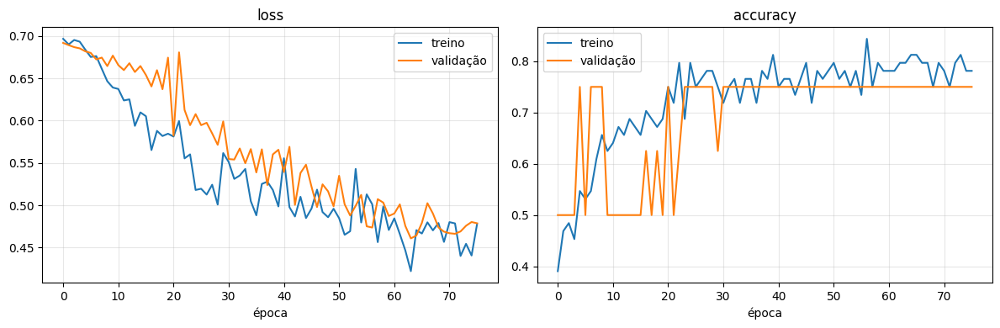

CNN — acurácia na validação: 0.750 | acurácia no teste: 0.375; loss: 1.154
                    precision    recall  f1-score   support

              vaca       0.33      0.25      0.29         4
equipamento_pesado       0.40      0.50      0.44         4

          accuracy                           0.38         8
         macro avg       0.37      0.38      0.37         8
      weighted avg       0.37      0.38      0.37         8



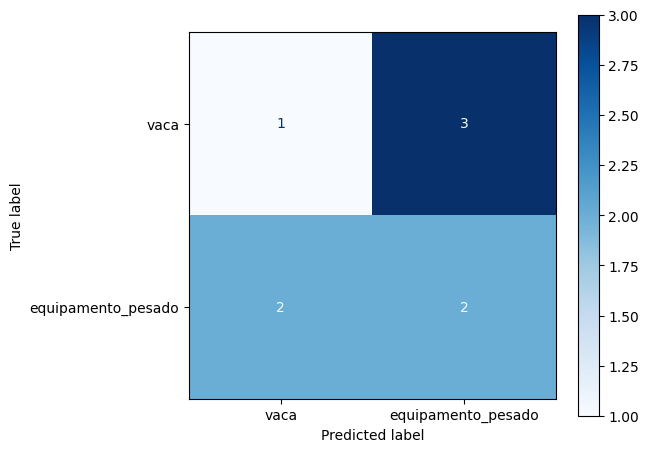

,imagem,classe_real,classe_prevista,prob_equipamento_pesado,acertou
0,71060961-vaca-em-pe-dentro-verde-pasto-gado-ag...,vaca,vaca,0.260768,True
1,8e658346-5a86-4f20-a876-557e24a75e31,equipamento_pesado,equipamento_pesado,0.999706,True
2,WhatsApp-Image-2020-06-23-at-11.19.49,vaca,equipamento_pesado,0.761981,False
3,pexels-christina99999-34582680,vaca,equipamento_pesado,0.579022,False
4,pexels-malama-mushitu-2148898721-34198067,vaca,equipamento_pesado,0.978788,False
5,pexels-ninobur-14911318,equipamento_pesado,vaca,0.274267,False
6,pexels-stokeron-27135349,equipamento_pesado,equipamento_pesado,0.749856,True
7,pexels-tomfisk-28840174,equipamento_pesado,vaca,0.301926,False


In [14]:
from IPython.display import Image as ImagemIPython

# ── Curvas de treino (ou a figura salva do treino original) ─────────────
if history_df is not None:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for ax, k in zip(axs, ['loss', 'accuracy']):
        ax.plot(history_df[k], label='treino')
        ax.plot(history_df['val_' + k], label='validação')
        ax.set_title(k); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(CNN_DIR / 'curvas_cnn.png', dpi=125)
    plt.show()
elif (CNN_DIR / 'curvas_cnn.png').exists():
    print('Curvas gravadas no treino original do modelo reaproveitado:')
    display(ImagemIPython(filename=str(CNN_DIR / 'curvas_cnn.png')))

# ── Avaliação na validação e no teste ───────────────────────────────────
val_loss_cnn, val_acc_cnn = cnn.evaluate(Xval, yval, verbose=0)
prob_cnn = cnn.predict(Xtest, verbose=0).ravel()             # probabilidade de equipamento_pesado
pred_cnn = (prob_cnn >= .5).astype(int)                      # limiar fixo de 0,5
loss_cnn, acc_cnn = cnn.evaluate(Xtest, ytest, verbose=0)
print(f'CNN — acurácia na validação: {val_acc_cnn:.3f} | acurácia no teste: {acc_cnn:.3f}; loss: {loss_cnn:.3f}')
print(classification_report(ytest, pred_cnn, labels=[0, 1], target_names=CLASSES, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(ytest, pred_cnn, labels=[0, 1]), display_labels=CLASSES).plot(cmap='Blues')
plt.tight_layout(); plt.savefig(CNN_DIR / 'matriz_confusao.png', dpi=125); plt.show()

# Predição imagem a imagem, para entender os erros
nomes = manifest_df[manifest_df.split == 'test'].stem.tolist()
resultados_cnn = pd.DataFrame({'imagem': nomes, 'classe_real': [CLASSES[i] for i in ytest],
                               'classe_prevista': [CLASSES[i] for i in pred_cnn],
                               'prob_equipamento_pesado': prob_cnn, 'acertou': pred_cnn == ytest})
resultados_cnn.to_csv(CNN_DIR / 'predicoes_teste.csv', index=False)
display(resultados_cnn)
_ = metricas_salvas.write_text(json.dumps({'acuracia_teste': float(acc_cnn), 'loss_teste': float(loss_cnn),
                                           'acuracia_validacao': float(val_acc_cnn),
                                           'tempo_treino_segundos': float(cnn_train_seconds),
                                           'epocas_executadas': cnn_epocas}, indent=2))

### 8.1 Por que a CNN do zero ficou abaixo do acaso?

O teste é balanceado (4 vacas e 4 equipamentos), então “chutar” sempre a mesma classe já daria **50%**. A CNN acertou **3 de 8 (37,5%)**, ou seja, **ficou abaixo do acaso**. A tabela de predições mostra que **3 das 4 vacas foram classificadas como equipamento** e 2 dos 4 equipamentos como vaca.

- **Poucos exemplos para aprender do zero:** 64 imagens não bastam para uma rede sem pré-treinamento aprender formas de animais e de máquinas. Uma hipótese natural seria a de que ela se apoia em atalhos como **cor e textura do fundo** (pasto verde, palha seca, céu).
- **Alta variância:** 75% na validação contra 37,5% no teste, com apenas 8 imagens em cada conjunto, mostra que trocar uma ou duas fotos muda muito o resultado.
- **Tarefa diferente:** a CNN classifica a foto inteira; ela não sabe *onde* está o objeto.

O **Ir Além** testou essas duas explicações. Remover o fundo automaticamente **não melhorou** a CNN do zero (média de 42,5% com e sem fundo, em 5 sementes), o que enfraquece a hipótese do atalho pelo cenário. Já a MobileNetV2 pré-treinada na ImageNet acertou 8 de 8. A principal causa do mau desempenho, portanto, é a **falta de dados para aprender do zero**, que o Transfer Learning resolve.

## 9. Medir tempo de inferência

Cronometramos cada modelo nas **mesmas 8 imagens de teste**. A leitura de arquivos, o carregamento dos modelos e a renderização ficam **fora** do cronômetro, e a GPU é sincronizada antes e depois de cada medição.

**Protocolo revisado.** Em uma primeira versão, cada modelo era aquecido e medido em sequência; o primeiro modelo medido absorvia parte da inicialização da GPU e parecia mais lento. Agora:
1. **todos** os modelos são aquecidos antes de qualquer medição;
2. fazemos 7 rodadas, alternando a ordem dos modelos a cada rodada;
3. reportamos a **mediana**, que é menos sensível a picos do Colab.

A CNN é executada em modo grafo (`tf.function`), forma usada em produção, para não medir apenas o custo de execução camada a camada do Python. Nas YOLOs, o tempo inclui o pré-processamento (redimensionamento) e o pós-processamento (NMS) feitos pelo próprio modelo. As YOLOs de 30 e 60 épocas têm **a mesma arquitetura**, então devem ter tempos equivalentes; a diferença entre elas serve como **controle do ruído** da medição.

In [15]:
# ── Carregar os modelos no mesmo dispositivo (GPU) ──────────────────────
DEVICE_TORCH = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.cuda.empty_cache()

def carregar_yolo(path):
    """Carrega um checkpoint YOLOv5 local via torch.hub, já com o limiar de confiança do projeto."""
    modelo = torch.hub.load(str(YOLO_DIR), 'custom', path=str(path), source='local', verbose=False)
    modelo = modelo.to(DEVICE_TORCH).eval()
    modelo.conf = CONF
    return modelo

modelos = {f'YOLO customizada {ep} ép.': carregar_yolo(RUNS_DRIVE / f'epocas_{ep}' / 'weights' / 'best.pt')
           for ep in EPOCHS_LIST}
modelos['YOLO padrão COCO'] = carregar_yolo(YOLO_DIR / 'yolov5s.pt')

arquivos = sorted((DATA / 'images' / 'test').glob('*.jpg'))
imgs_rgb = []
for p in arquivos:                                            # imagens já em memória (fora do cronômetro)
    with Image.open(p) as im:
        imgs_rgb.append(np.asarray(im.convert('RGB').copy()))

def sync_torch():
    """Espera a GPU terminar o trabalho pendente antes de ler o relógio."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def yolo_fn(m):
    """Função de inferência de uma YOLO, sem cálculo de gradientes."""
    def f(a):
        with torch.inference_mode():
            return m(a, size=IMG_SIZE)
    return f

cnn_grafo = tf.function(lambda x: cnn(x, training=False))     # CNN compilada em modo grafo
funcoes = {nome: yolo_fn(m) for nome, m in modelos.items()}
funcoes['CNN do zero'] = lambda a: cnn_grafo(a[None]).numpy()  # .numpy() força a sincronização do TF
entradas = {nome: imgs_rgb for nome in modelos}
entradas['CNN do zero'] = list(Xtest)

# 1) Aquecimento global de todos os modelos
for nome, fn in funcoes.items():
    for a in entradas[nome][:3]:
        fn(a)
sync_torch()

# 2) Rodadas alternando a ordem dos modelos
RODADAS = 7
tempos_rodadas = {nome: [] for nome in funcoes}
sequencia = list(funcoes)
for r in range(RODADAS):
    for nome in (sequencia if r % 2 == 0 else sequencia[::-1]):
        sync_torch()
        inicio = time.perf_counter()
        for a in entradas[nome]:
            funcoes[nome](a)
        sync_torch()
        tempos_rodadas[nome].append((time.perf_counter() - inicio) * 1000 / len(entradas[nome]))

# 3) Mediana por modelo (ms por imagem)
latency_ms = {nome: float(np.median(v)) for nome, v in tempos_rodadas.items()}
lat_df = pd.DataFrame([{'modelo': k, 'ms_por_imagem_mediana': round(np.median(v), 2),
                        'min': round(min(v), 2), 'max': round(max(v), 2)} for k, v in tempos_rodadas.items()])
lat_df.to_csv(RESULTS / 'tempo_inferencia.csv', index=False)
display(lat_df)

YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


,modelo,ms_por_imagem_mediana,min,max
0,YOLO customizada 30 ép.,10.05,9.18,18.41
1,YOLO customizada 60 ép.,9.51,9.31,12.06
2,YOLO padrão COCO,9.67,9.37,11.05
3,CNN do zero,1.65,1.47,1.70


In [16]:
# ── Interpretação automática dos tempos medidos nesta execução ──────────
t30, t60 = latency_ms['YOLO customizada 30 ép.'], latency_ms['YOLO customizada 60 ép.']
ruido = abs(t30 - t60) / min(t30, t60) * 100                  # diferença entre modelos idênticos
tmin, tmax = min(latency_ms.values()), max(latency_ms.values())
controle = ('ficaram equivalentes, como esperado para modelos de mesma arquitetura'
            if ruido < 15 else 'diferiram mais que o esperado, o que indica variação do ambiente; vale repetir a medição')
texto_latencia = (
    f"**Leitura dos tempos (mediana de {RODADAS} rodadas, GPU T4):** "
    + '; '.join(f'{k}: {v:.2f} ms' for k, v in latency_ms.items()) + ' por imagem. '
    f"As YOLOs de 30 e 60 épocas {controle} (diferença de {ruido:.0f}%). "
    f"Diferenças dessa ordem entre os demais modelos também não devem ser lidas como vantagem real. "
    f"Na prática, todas as abordagens processam uma imagem entre {tmin:.1f} e {tmax:.1f} ms, "
    f"o equivalente a cerca de {1000/tmax:.0f} a {1000/tmin:.0f} imagens por segundo nesta GPU — "
    f"suficiente para monitoramento por câmera em tempo real. O critério de escolha, portanto, "
    f"é a capacidade de cada modelo (localizar e nomear objetos), e não a velocidade."
)
display(Markdown(texto_latencia))

**Leitura dos tempos (mediana de 7 rodadas, GPU T4):** YOLO customizada 30 ép.: 10.05 ms; YOLO customizada 60 ép.: 9.51 ms; YOLO padrão COCO: 9.67 ms; CNN do zero: 1.65 ms por imagem. As YOLOs de 30 e 60 épocas ficaram equivalentes, como esperado para modelos de mesma arquitetura (diferença de 6%). Diferenças dessa ordem entre os demais modelos também não devem ser lidas como vantagem real. Na prática, todas as abordagens processam uma imagem entre 1.7 e 10.1 ms, o equivalente a cerca de 99 a 606 imagens por segundo nesta GPU — suficiente para monitoramento por câmera em tempo real. O critério de escolha, portanto, é a capacidade de cada modelo (localizar e nomear objetos), e não a velocidade.

## 10. Resultados integrados

Tabela de comparação: **mAP/P/R oficiais** para a YOLO customizada; **F1 de detecção da classe vaca** para todas as YOLOs (mesmo protocolo de IoU); **acurácia da CNN** somente na tarefa de classificação. Números de natureza diferente ficam em colunas diferentes. O texto abaixo da tabela é gerado a partir das medições **desta execução**.

In [17]:
# ── Tabela final, com uma coluna para cada tipo de métrica ─────────────
T = metrics_df.query("split=='test' and classe=='all'").set_index('epocas')   # métricas de teste
V = metrics_df.query("split=='val' and classe=='all'").set_index('epocas')    # métricas de validação
res = []
for ep in EPOCHS_LIST:
    nome = f'YOLO customizada {ep} ép.'
    rec = cow_comparison.query('modelo==@nome and IoU_min==0.5').iloc[0]
    res.append({'modelo': nome, 'tarefa': 'detecção 2 classes',
                'mAP50_teste': float(T.loc[ep, 'mAP50']), 'mAP50_95_teste': float(T.loc[ep, 'mAP50_95']),
                'precision_teste': float(T.loc[ep, 'precision']), 'recall_teste': float(T.loc[ep, 'recall']),
                'F1_vaca_IoU50': float(rec.F1), 'acuracia_classificacao': np.nan,
                'treino_min': train_seconds[ep] / 60, 'inferencia_ms_img': latency_ms[nome]})
rec = cow_comparison.query("modelo=='YOLO padrão COCO (cow)' and IoU_min==0.5").iloc[0]
res.append({'modelo': 'YOLO padrão COCO', 'tarefa': 'detecção COCO (vaca comparável)',
            'mAP50_teste': np.nan, 'mAP50_95_teste': np.nan, 'precision_teste': np.nan, 'recall_teste': np.nan,
            'F1_vaca_IoU50': float(rec.F1), 'acuracia_classificacao': np.nan,
            'treino_min': 0., 'inferencia_ms_img': latency_ms['YOLO padrão COCO']})
res.append({'modelo': 'CNN do zero', 'tarefa': 'classificação de imagem inteira',
            'mAP50_teste': np.nan, 'mAP50_95_teste': np.nan, 'precision_teste': np.nan, 'recall_teste': np.nan,
            'F1_vaca_IoU50': np.nan, 'acuracia_classificacao': float(acc_cnn),
            'treino_min': cnn_train_seconds / 60, 'inferencia_ms_img': latency_ms['CNN do zero']})
final_df = pd.DataFrame(res)
final_df.to_csv(RESULTS / 'comparacao_final.csv', index=False)
display(final_df.round(3).fillna('—'))

# Resumo textual gerado com os números desta execução
ganho_val = float(V.loc[60, 'mAP50'] - V.loc[30, 'mAP50'])
ganho_teste = float(T.loc[60, 'mAP50'] - T.loc[30, 'mAP50'])
melhor_validacao = int(V['mAP50'].idxmax())
resumo = (
    f'**Comparação (validação):** mAP@0.5 mudou de {V.loc[30, "mAP50"]:.3f} (30 épocas) para '
    f'{V.loc[60, "mAP50"]:.3f} (60 épocas), diferença {ganho_val:+.3f}. '
    f'No teste, a mudança foi de {T.loc[30, "mAP50"]:.3f} para {T.loc[60, "mAP50"]:.3f} ({ganho_teste:+.3f}). '
    f'Os treinamentos consumiram {train_seconds[30]/60:.1f} e {train_seconds[60]/60:.1f} minutos. '
    f'**Pelo mAP de validação**, o experimento de {melhor_validacao} épocas teve o resultado mais alto. '
    f'A CNN atingiu acurácia de {acc_cnn:.3f} no teste de 8 imagens, em uma tarefa diferente (classificação).'
)
display(Markdown(resumo))
_ = (RESULTS / 'resumo_numerico.md').write_text(resumo, encoding='utf8')

,modelo,tarefa,mAP50_teste,mAP50_95_teste,precision_teste,recall_teste,F1_vaca_IoU50,acuracia_classificacao,treino_min,inferencia_ms_img
0,YOLO customizada 30 ép.,detecção 2 classes,0.819,0.555,0.911,0.575,0.8,—,1.464,10.052
1,YOLO customizada 60 ép.,detecção 2 classes,0.924,0.637,0.867,0.786,0.8,—,2.011,9.514
2,YOLO padrão COCO,detecção COCO (vaca comparável),—,—,—,—,0.667,—,0.000,9.667
3,CNN do zero,classificação de imagem inteira,—,—,—,—,—,0.375,0.343,1.651


**Comparação (validação):** mAP@0.5 mudou de 0.964 (30 épocas) para 0.981 (60 épocas), diferença +0.017. No teste, a mudança foi de 0.819 para 0.924 (+0.105). Os treinamentos consumiram 1.5 e 2.0 minutos. **Pelo mAP de validação**, o experimento de 60 épocas teve o resultado mais alto. A CNN atingiu acurácia de 0.375 no teste de 8 imagens, em uma tarefa diferente (classificação).

### 10.1 Discussão crítica por critério

**Facilidade de uso / integração:** a YOLO padrão roda sem rotular nem treinar, mas sua taxonomia COCO não cobre o equipamento agrícola escolhido. A YOLO customizada exige anotação de caixas, um pipeline de treino e GPU; em compensação, devolve **classe, localização e confiança** das duas categorias. A CNN em Keras exige apenas uma classe por foto e é simples de integrar como classificador, mas **não delimita** objetos.

**Precisão:** comparamos 30 e 60 épocas pela **validação** antes de interpretar o teste. Na detecção, usamos mAP, P, R, F1 e exemplos de erros, incluindo a diferença entre IoU 0,50 e 0,75. A coluna `F1_vaca_IoU50` é a régua comum possível entre as três YOLOs. A CNN é interpretada pela acurácia e pela matriz de confusão, não pelo mAP.

**Tempo de treinamento:** a YOLO padrão não foi treinada neste projeto (0 min de customização); a YOLO customizada requer GPU e anotação prévia; a CNN do zero usa uma arquitetura pequena e entrada menor. Comparamos os **tempos efetivamente medidos**, sem concluir que uma arquitetura será sempre mais rápida.

**Tempo de inferência:** veja a interpretação gerada na seção 9. As entradas têm tamanhos diferentes, os frameworks têm custos próprios e os tempos variam entre execuções; por isso usamos as YOLOs de 30 e 60 épocas como controle do ruído.

**Limites da amostra:** 8 fotos de teste são insuficientes para generalização estatística. Na classificação, um erro altera a acurácia em 12,5 pontos percentuais. A rotulação parcial de cenas complexas gera *falsos positivos aparentes*. A classe de equipamentos é visualmente heterogênea, e a redução para 1280 px pode apagar detalhes de objetos distantes.

In [18]:
# ── Relatório final em Markdown, com os resultados reais desta execução ─
conclusao = f"""# Relatório de resultados — FarmTech Fase 6

## Comparação de épocas
- mAP@0.5 na validação: 30={V.loc[30,'mAP50']:.3f} | 60={V.loc[60,'mAP50']:.3f} | diferença={ganho_val:+.3f}.
- mAP@0.5 no teste: 30={T.loc[30,'mAP50']:.3f} | 60={T.loc[60,'mAP50']:.3f} | diferença={ganho_teste:+.3f}.
- Tempos de treino: 30={train_seconds[30]/60:.2f} min | 60={train_seconds[60]/60:.2f} min.
- A versão de {melhor_validacao} épocas apresentou o maior mAP@0.5 na validação.

## Comparação de abordagens
- A YOLO padrão é simples para vacas, mas não contempla a classe `equipamento_pesado`.
- CNN do zero: acurácia no teste={acc_cnn:.3f}, loss={loss_cnn:.3f}, tempo de treino={cnn_train_seconds/60:.2f} min.
- Inferência (mediana, ms/imagem): {', '.join(f'{k}={v:.2f}' for k, v in latency_ms.items())}.

## Limitações e recomendação responsável
A amostra é pequena (8 imagens de teste), com cenas parcialmente anotadas.
Métricas de detecção podem contar como falsos positivos objetos reais não marcados.
A CNN só classifica imagens; não encontra nem conta objetos.
Para localização e contagem na fazenda, a YOLO customizada é a arquitetura funcionalmente adequada;
antes de uma implantação real, ampliar a base, revisar todas as caixas, medir em novos locais e revisar a classe de máquinas.
"""
_ = (RESULTS / 'relatorio_resultados.md').write_text(conclusao, encoding='utf8')
display(Markdown(conclusao))

# Relatório de resultados — FarmTech Fase 6

## Comparação de épocas
- mAP@0.5 na validação: 30=0.964 | 60=0.981 | diferença=+0.017.
- mAP@0.5 no teste: 30=0.819 | 60=0.924 | diferença=+0.105.
- Tempos de treino: 30=1.46 min | 60=2.01 min.
- A versão de 60 épocas apresentou o maior mAP@0.5 na validação.

## Comparação de abordagens
- A YOLO padrão é simples para vacas, mas não contempla a classe `equipamento_pesado`.
- CNN do zero: acurácia no teste=0.375, loss=1.154, tempo de treino=0.34 min.
- Inferência (mediana, ms/imagem): YOLO customizada 30 ép.=10.05, YOLO customizada 60 ép.=9.51, YOLO padrão COCO=9.67, CNN do zero=1.65.

## Limitações e recomendação responsável
A amostra é pequena (8 imagens de teste), com cenas parcialmente anotadas.
Métricas de detecção podem contar como falsos positivos objetos reais não marcados.
A CNN só classifica imagens; não encontra nem conta objetos.
Para localização e contagem na fazenda, a YOLO customizada é a arquitetura funcionalmente adequada;
antes de uma implantação real, ampliar a base, revisar todas as caixas, medir em novos locais e revisar a classe de máquinas.


### 10.2 Análise final dos resultados

**Configuração dos experimentos.** Os treinamentos YOLOv5s de 30 e 60 épocas começaram dos mesmos pesos pré-treinados, com as mesmas classes, imagens, resolução (640), tamanho de lote (8) e semente. A base tem 64 imagens de treino, 8 de validação e 8 de teste.

**Validação e teste — métricas oficiais da YOLO.** Na validação, o **mAP@0.5** passou de **0,964** (30 épocas) para **0,981** (60 épocas) — um ganho pequeno, já perto do teto, porque 8 imagens de validação saturam rapidamente. No teste, o ganho foi maior: o mAP@0.5 subiu de **0,819** para **0,924**, e o **mAP@0.5:0.95**, de **0,555** para **0,637**, indicando caixas mais bem ajustadas. O *recall* no teste subiu de **0,575** para **0,786**, enquanto a *precision* caiu levemente, de **0,911** para **0,867**: o modelo de 60 épocas encontra mais objetos, ao custo de alguns alarmes a mais. A escolha de 60 épocas se apoia no **mAP de validação**, definido antes de olhar o teste, e o teste confirmou essa escolha. Os tempos de treino foram **1,46 min** e **2,01 min**, sem contar o tempo de rotulação e preparação da base.

**Verificação com limiar fixo (confiança 0,25).** Na análise das **duas classes juntas** nas oito imagens de teste, com **IoU ≥ 0,50**, as duas versões **empataram**: **8 TP, 4 FP e 1 FN** (*F1* = **0,762**). Com o critério mais rigoroso, **IoU ≥ 0,75**, a de 60 épocas foi melhor (*F1* **0,571** contra **0,476**), e o IoU médio dos acertos também foi maior (0,824 contra 0,798). Ou seja, a diferença entre as versões está mais na **qualidade do enquadramento** do que na quantidade de objetos encontrados, o que é coerente com o ganho de mAP@0.5:0.95. Parte dos FP são objetos reais não rotulados (seção 5.1).

**Classe vaca sob o mesmo protocolo (confiança 0,25; IoU ≥ 0,50).** O F1 foi **0,800** para as duas YOLOs customizadas e **0,667** para a **YOLO padrão COCO**. Esse valor da COCO está subestimado: como mostra a seção 6.1, vários dos seus “falsos positivos” são vacas reais não rotuladas. Além disso, a COCO desenha caixas de vaca muito justas (IoU médio de 0,946 e F1 inalterado com IoU ≥ 0,75), um ponto a favor do modelo pronto, treinado com milhares de fotos de bovinos. Ainda assim, ela não oferece uma categoria para `equipamento_pesado` — tratar `truck` como equipamento, em caráter exploratório, rendeu F1 de 0,696 nas duas classes — e, portanto, não substitui o detector customizado.

**CNN construída do zero.** A CNN executou **76 épocas** (parada antecipada), levou cerca de **0,34 min** e obteve **0,750** de acurácia na validação e **0,375 no teste (3/8 imagens corretas)**, com *loss* de teste **1,154** — **abaixo dos 50% de um palpite** em um teste balanceado. Poucos exemplos e a ausência de pré-treinamento explicam a baixa generalização; o Ir Além mostrou que remover o fundo não resolve o problema, enquanto o Transfer Learning resolve (seção 8.1). Trata-se de classificação da foto inteira, e não de detecção; sua acurácia não deve ser comparada diretamente com o mAP da YOLO.

**Tempo de inferência.** A leitura gerada na seção 9 mostra os tempos medianos desta execução. Como as YOLOs de 30 e 60 épocas têm a mesma arquitetura, a diferença entre elas indica o tamanho do ruído da medição; diferenças dessa ordem entre os modelos não são vantagem real. Todas as abordagens são rápidas o bastante para uso em tempo real na GPU, então a escolha deve ser feita pela capacidade de cada modelo.

**Limitações e implicações.** A base de teste contém apenas oito imagens e nove caixas rotuladas. Algumas cenas têm objetos reais sem anotação, e as máquinas formam uma classe heterogênea. Portanto, um mAP elevado em uma amostra tão pequena **não comprova robustez operacional**. Antes de uma implantação real, seriam necessárias mais imagens e locais, revisão dos rótulos, reavaliação dos parâmetros e testes de generalização.

## 11. Conclusão e encaminhamento ao cliente fictício

**Resultado da prova de conceito.** A YOLOv5s customizada com **60 épocas** obteve o maior **mAP@0.5 de validação (98,1% contra 96,4%)** e também os melhores resultados no teste: **mAP@0.5 de 92,4%** (contra 81,9%) e **mAP@0.5:0.95 de 63,7%** (contra 55,5%). O *recall* de teste subiu de **57,5% para 78,6%**, com uma pequena queda de *precision* (**91,1% → 86,7%**).

**Contraponto importante.** Na avaliação própria por correspondência de caixas, com **confiança 0,25 e IoU ≥ 0,50**, as duas versões **empataram** (8 TP, 4 FP, 1 FN; F1 0,762). A vantagem da versão de 60 épocas aparece no critério mais rigoroso (IoU ≥ 0,75: F1 0,571 contra 0,476), ou seja, em caixas mais justas. Com 8 imagens de teste, essas diferenças são indícios, não prova estatística.

A YOLO padrão detectou bem as vacas — inclusive as não rotuladas e com caixas muito precisas —, mas classifica as máquinas como `truck` e não atende à classe de equipamentos agrícolas definida no projeto. A CNN treinada do zero teve **37,5% de acurácia no teste (3 de 8 fotos), abaixo do acaso**, resultado insuficiente para uma classificação confiável e não comparável diretamente ao mAP da YOLO.

**Recomendação à FarmTech Solutions.** Utilizar a **YOLO customizada de 60 épocas** como demonstração de localização de vacas e equipamentos, com conferência humana dos resultados. Não recomendar implantação em produção apenas com esta base: é preciso ampliar e diversificar as imagens, completar a rotulação das cenas com vários objetos, repetir os testes em novos cenários e definir critérios de qualidade adequados ao uso real.

**Limitações:** oito imagens de teste, rótulos parciais, heterogeneidade visual das máquinas, diferença entre as tarefas de detecção e classificação e medições de latência dependentes do ambiente.